In [50]:
import pandas as pd
from sklearn.model_selection import train_test_split 
from sklearn import preprocessing 
import matplotlib.pyplot as plt

link = 'D:\\СИИ_Курсовая\\seattle-weather.csv'
y_name = 'weather' 
df = pd.read_csv(link)
class_names = df[y_name].unique()
df


,date,precipitation,temp_max,temp_min,wind,weather
0,2012-01-01,0.0,12.8,5.0,4.7,drizzle
1,2012-01-02,10.9,10.6,2.8,4.5,rain
2,2012-01-03,0.8,11.7,7.2,2.3,rain
3,2012-01-04,20.3,12.2,5.6,4.7,rain
4,2012-01-05,1.3,8.9,2.8,6.1,rain
...,...,...,...,...,...,...
1456,2015-12-27,8.6,4.4,1.7,2.9,rain
1457,2015-12-28,1.5,5.0,1.7,1.3,rain
1458,2015-12-29,0.0,7.2,0.6,2.6,fog
1459,2015-12-30,0.0,5.6,-1.0,3.4,sun


In [51]:
df = df.drop('date', axis=1) 
df 

,precipitation,temp_max,temp_min,wind,weather
0,0.0,12.8,5.0,4.7,drizzle
1,10.9,10.6,2.8,4.5,rain
2,0.8,11.7,7.2,2.3,rain
3,20.3,12.2,5.6,4.7,rain
4,1.3,8.9,2.8,6.1,rain
...,...,...,...,...,...
1456,8.6,4.4,1.7,2.9,rain
1457,1.5,5.0,1.7,1.3,rain
1458,0.0,7.2,0.6,2.6,fog
1459,0.0,5.6,-1.0,3.4,sun


In [52]:
types = ['int','int64','int32','float','float32','float64'] 
tch = lambda c: any([str(c.dtype)==t for t in types]) 
for col in df.columns: 
    if not tch(df[col]): 
        df[col] = df[col].astype(str) 
        for i, uniq in enumerate(df[col].unique()):  
            df[col] = df[col].replace(uniq,str(i)) 
        df[col] = df[col].astype(int)
df 

,precipitation,temp_max,temp_min,wind,weather
0,0.0,12.8,5.0,4.7,0
1,10.9,10.6,2.8,4.5,1
2,0.8,11.7,7.2,2.3,1
3,20.3,12.2,5.6,4.7,1
4,1.3,8.9,2.8,6.1,1
...,...,...,...,...,...
1456,8.6,4.4,1.7,2.9,1
1457,1.5,5.0,1.7,1.3,1
1458,0.0,7.2,0.6,2.6,4
1459,0.0,5.6,-1.0,3.4,2


In [54]:
print(f"Признаки в датасете: {list(df.columns)}")
print(f"Общее количество образов: {len(df)} записи \n")
print(f"Целевой признак - {y_name}")
value = df[y_name].value_counts()
print(f"Количество классов данного признака: {len(value)} \n")


Признаки в датасете: ['precipitation', 'temp_max', 'temp_min', 'wind', 'weather']
Общее количество образов: 1461 записи 

Целевой признак - weather
Количество классов данного признака: 5 



In [55]:
print(f"Признаки в датасете: {list(df.columns)}")
print(f"Общее количество образов: {len(df)} записи \n")
print(f"Целевой признак - {y_name}")
value = df[y_name].value_counts()
print(f"Количество классов данного признака: {len(value)} \n")
print(f"Число образов каждого класса в {y_name}:")
zero = len(df[df['weather'] == 0])
one = len(df[df['weather'] == 1])
two = len(df[df['weather'] == 2])
three = len(df[df['weather'] == 3])
four = len(df[df['weather'] == 4])
print(f"0 - drizzle, {zero} образов {((zero / len(df)) * 100):.2f}% ")
print(f"1 - rain, {one} образов {((one / len(df)) * 100):.2f}% ")
print(f"2 - sun, {two} образов {((two / len(df)) * 100):.2f}% ")
print(f"3 - snow, {three} образов {((three / len(df)) * 100):.2f}% ")
print(f"4 - fog, {four} образов {((four / len(df)) * 100):.2f}% ")


Признаки в датасете: ['precipitation', 'temp_max', 'temp_min', 'wind', 'weather']
Общее количество образов: 1461 записи 

Целевой признак - weather
Количество классов данного признака: 5 

Число образов каждого класса в weather:
0 - drizzle, 53 образов 3.63% 
1 - rain, 641 образов 43.87% 
2 - sun, 640 образов 43.81% 
3 - snow, 26 образов 1.78% 
4 - fog, 101 образов 6.91% 


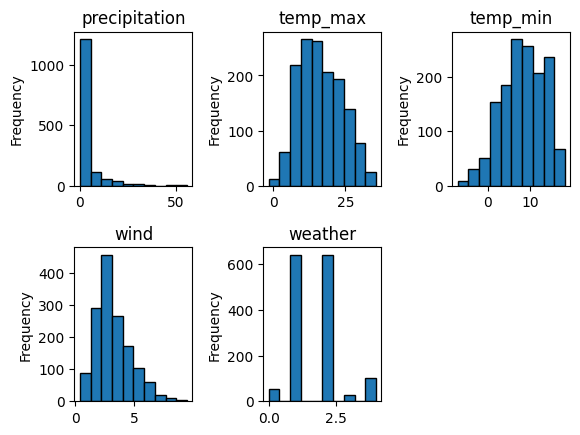

In [56]:
selected_cols = ['precipitation', 'temp_max', 'temp_min', 'wind', 'weather']
for i, col in enumerate(selected_cols):
    plt.subplot(2, 3, i+1)
    df[col].plot(kind='hist', edgecolor='black')
    plt.title(col)

plt.subplots_adjust(wspace=0.6, hspace=0.4)
plt.show()


In [57]:
from sklearn.model_selection import train_test_split 
import pandas as pd
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score 

In [58]:
X = df.drop(y_name, axis=1)
y = df[y_name]
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.67, random_state=42)

In [59]:
def evaluate_classifiers(X_train, X_test, y_train, y_test):
    classifiers = {
        'Опорных векторов с линейным ядром': SVC(kernel='linear'),
        'Опорных векторов с полиномиальным ядром': SVC(kernel='poly'),
        'Опорных векторов с RBF ядром': SVC(kernel='rbf'),
        'k-ближайших соседей': KNeighborsClassifier(),
        'Древо решений': DecisionTreeClassifier(),
        'Случайный лес': RandomForestClassifier(),
        'Градиентный бустинг': GradientBoostingClassifier(),
        'Наивный байесовский классификатор': GaussianNB()
    }
    best_classifier = None
    best_score = 0
    best_name = ""
    
    print("===Результаты классификации===")
    
    for name, clf in classifiers.items():
        clf.fit(X_train, y_train)
        
        train_pred = clf.predict(X_train)
        test_pred = clf.predict(X_test)
        
        train_acc = accuracy_score(y_train, train_pred) * 100
        test_acc = accuracy_score(y_test, test_pred) * 100
        
        train_error = 100 - train_acc
        test_error = 100 - test_acc
        
        overfitting = ""
        if (train_acc - test_acc) > 20:
            overfitting = "          ПЕРЕОБУЧЕНИЕ!"
        
        print(f"\n==={name}===")
        print(f"Ошибка на обучающих: {train_error:.1f}%")
        print(f"Ошибка на тестовых: {test_error:.1f}%{overfitting}")
        
        if test_acc > best_score:
            best_score = test_acc
            best_classifier = clf
            best_name = name
    print(f"\nЛучший классификатор: {best_name}")
    print(f"Точность лучшего классификатора на тестовых данных: {best_score:.1f}%")
    
    return best_classifier

In [60]:
best_model = evaluate_classifiers(X_train, X_test, y_train, y_test)

===Результаты классификации===

===Опорных векторов с линейным ядром===
Ошибка на обучающих: 14.5%
Ошибка на тестовых: 15.3%

===Опорных векторов с полиномиальным ядром===
Ошибка на обучающих: 23.7%
Ошибка на тестовых: 22.2%

===Опорных векторов с RBF ядром===
Ошибка на обучающих: 22.3%
Ошибка на тестовых: 21.9%

===k-ближайших соседей===
Ошибка на обучающих: 19.3%
Ошибка на тестовых: 22.2%

===Древо решений===
Ошибка на обучающих: 0.2%
Ошибка на тестовых: 26.1%          ПЕРЕОБУЧЕНИЕ!

===Случайный лес===
Ошибка на обучающих: 0.2%
Ошибка на тестовых: 16.8%

===Градиентный бустинг===
Ошибка на обучающих: 8.3%
Ошибка на тестовых: 16.6%

===Наивный байесовский классификатор===
Ошибка на обучающих: 15.1%
Ошибка на тестовых: 15.3%

Лучший классификатор: Опорных векторов с линейным ядром
Точность лучшего классификатора на тестовых данных: 84.7%


In [61]:
from sklearn import preprocessing
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

def plot_variance(pca, figwidth=8, dpi=100):
    fig, axs = plt.subplots(1, 2)
    n = pca.n_components_
    grid = np.arange(1, n + 1)
    evr = pca.explained_variance_ratio_
    axs[0].bar(grid, evr)
    label, title = 'Компонент', 'Объясненной дисперсии'
    axs[0].set(xlabel=label, title=title, ylim=(0.0, 1.0))
    cv = np.cumsum(evr)
    axs[1].plot(np.r_[0, grid], np.r_[0, cv], "o-")
    title = 'Совокупной дисперсии'
    axs[1].set(xlabel=label, title=title, ylim=(0.0, 1.0))
    fig.suptitle('Доли дисперсии (от 0 до 1):')
    fig.set(figwidth=figwidth, dpi=dpi)
    plt.show()
def apply_normalization(X_train, X_test):
    sc = preprocessing.StandardScaler()
    Xs_train = sc.fit_transform(X_train)
    Xs_test = sc.transform(X_test)
    return Xs_train, Xs_test

In [62]:
def evaluate_normalization(X_train, X_test, y_train, y_test):
    Xs_train, Xs_test = apply_normalization(X_train, X_test)
    print("\n=== Оценка после нормализации ===")
    evaluate_classifiers(Xs_train, Xs_test, y_train, y_test)

evaluate_normalization(X_train, X_test, y_train, y_test)


=== Оценка после нормализации ===
===Результаты классификации===

===Опорных векторов с линейным ядром===
Ошибка на обучающих: 21.6%
Ошибка на тестовых: 20.7%

===Опорных векторов с полиномиальным ядром===
Ошибка на обучающих: 26.8%
Ошибка на тестовых: 25.5%

===Опорных векторов с RBF ядром===
Ошибка на обучающих: 21.7%
Ошибка на тестовых: 23.0%

===k-ближайших соседей===
Ошибка на обучающих: 21.1%
Ошибка на тестовых: 25.7%

===Древо решений===
Ошибка на обучающих: 0.2%
Ошибка на тестовых: 25.9%          ПЕРЕОБУЧЕНИЕ!

===Случайный лес===
Ошибка на обучающих: 0.2%
Ошибка на тестовых: 17.2%

===Градиентный бустинг===
Ошибка на обучающих: 8.4%
Ошибка на тестовых: 17.2%

===Наивный байесовский классификатор===
Ошибка на обучающих: 15.1%
Ошибка на тестовых: 15.3%

Лучший классификатор: Наивный байесовский классификатор
Точность лучшего классификатора на тестовых данных: 84.7%


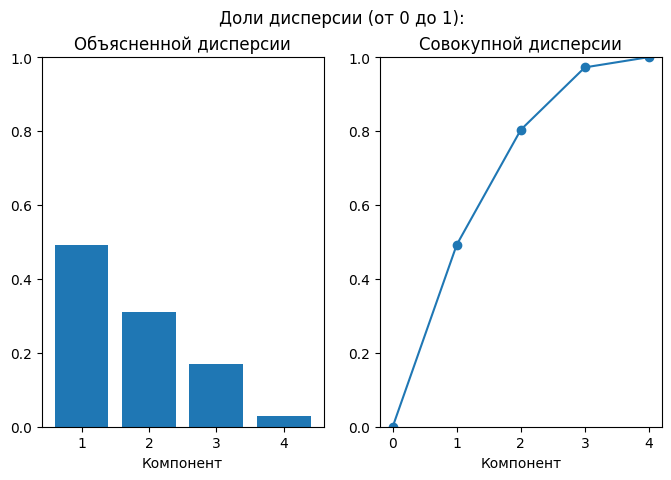


===Результаты после МГК с нормализацией===
===Результаты классификации===

===Опорных векторов с линейным ядром===
Ошибка на обучающих: 21.6%
Ошибка на тестовых: 20.7%

===Опорных векторов с полиномиальным ядром===
Ошибка на обучающих: 26.8%
Ошибка на тестовых: 25.5%

===Опорных векторов с RBF ядром===
Ошибка на обучающих: 21.7%
Ошибка на тестовых: 23.0%

===k-ближайших соседей===
Ошибка на обучающих: 21.1%
Ошибка на тестовых: 25.9%

===Древо решений===
Ошибка на обучающих: 0.2%
Ошибка на тестовых: 35.8%          ПЕРЕОБУЧЕНИЕ!

===Случайный лес===
Ошибка на обучающих: 0.2%
Ошибка на тестовых: 26.7%          ПЕРЕОБУЧЕНИЕ!

===Градиентный бустинг===
Ошибка на обучающих: 4.3%
Ошибка на тестовых: 25.7%          ПЕРЕОБУЧЕНИЕ!

===Наивный байесовский классификатор===
Ошибка на обучающих: 32.9%
Ошибка на тестовых: 33.1%

Лучший классификатор: Опорных векторов с линейным ядром
Точность лучшего классификатора на тестовых данных: 79.3%


In [63]:
def evaluate_pca_with_normalization(X_train, X_test, y_train, y_test):
    sc = preprocessing.StandardScaler()
    Xs_train = sc.fit_transform(X_train)
    Xs_test = sc.transform(X_test)
    
    pca = PCA(n_components=4)
    Xspca_train = pca.fit_transform(Xs_train)
    Xspca_test = pca.transform(Xs_test)
    
    plot_variance(pca)
    
    print("\n===Результаты после МГК с нормализацией===")
    evaluate_classifiers(Xspca_train, Xspca_test, y_train, y_test)

evaluate_pca_with_normalization(X_train, X_test, y_train, y_test)

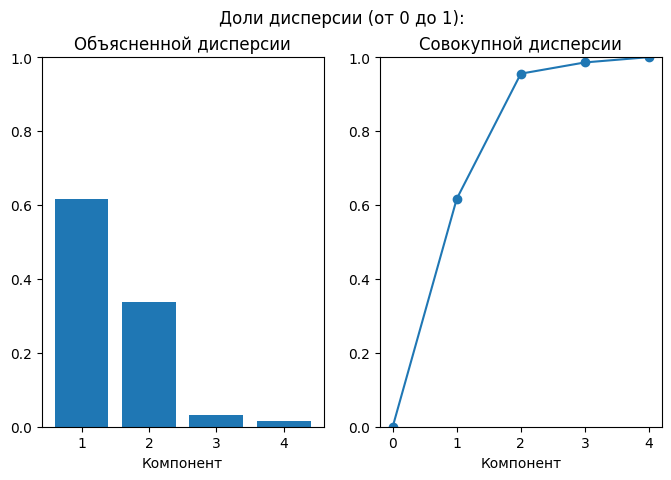


===Результаты после МГК без нормализации===
===Результаты классификации===

===Опорных векторов с линейным ядром===
Ошибка на обучающих: 14.5%
Ошибка на тестовых: 15.3%

===Опорных векторов с полиномиальным ядром===
Ошибка на обучающих: 29.1%
Ошибка на тестовых: 29.2%

===Опорных векторов с RBF ядром===
Ошибка на обучающих: 21.9%
Ошибка на тестовых: 21.3%

===k-ближайших соседей===
Ошибка на обучающих: 19.2%
Ошибка на тестовых: 22.2%

===Древо решений===
Ошибка на обучающих: 0.2%
Ошибка на тестовых: 29.4%          ПЕРЕОБУЧЕНИЕ!

===Случайный лес===
Ошибка на обучающих: 0.2%
Ошибка на тестовых: 20.3%          ПЕРЕОБУЧЕНИЕ!

===Градиентный бустинг===
Ошибка на обучающих: 3.9%
Ошибка на тестовых: 21.1%

===Наивный байесовский классификатор===
Ошибка на обучающих: 32.9%
Ошибка на тестовых: 33.5%

Лучший классификатор: Опорных векторов с линейным ядром
Точность лучшего классификатора на тестовых данных: 84.7%


In [64]:
def evaluate_pca_without_normalization(X_train, X_test, y_train, y_test):
    pca = PCA(n_components=4)
    Xpca_train = pca.fit_transform(X_train)
    Xpca_test = pca.transform(X_test)
    
    plot_variance(pca)
    
    print("\n===Результаты после МГК без нормализации===")
    evaluate_classifiers(Xpca_train, Xpca_test, y_train, y_test)

evaluate_pca_without_normalization(X_train, X_test, y_train, y_test)